# ۰۴ - تحلیل مشتریان و بازار جغرافیایی

پاسخ به سؤال‌های بخش ۶ صورت‌مسئله: تعداد مشتریان یکتا، توزیع جغرافیایی و تمرکز بازار.

## ۲. سؤال‌های کسب‌وکاری

1. تعداد مشتریان یکتا چقدر است و تفاوت آن با تعداد ردیف چیست؟
2. تعداد مشتریان هر ایالت چقدر است و ده ایالت اول کدام‌اند؟
3. سهم پنج ایالت اول از کل مشتریان چقدر است؟
4. کدام شهرها بیشترین مشتری را دارند؟
5. آیا سهم ایالت‌ها از مشتریان و از سفارش‌ها متفاوت است؟

## ۱. عنوان و هدف

پاسخ به سؤال‌های بخش ۶ صورت‌مسئله: تعداد مشتریان یکتا، توزیع جغرافیایی و تمرکز بازار.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

شمارش مشتری با `customer_unique_id` انجام می‌شود، چون `customer_id` در این دیتاست معادل یک سفارش است و نه یک شخص.

## ۶. تحلیل عددی

### ۶.۱ تعداد مشتریان

In [2]:
display(pd.Series(M.customer_overview(ds), name="value"))

customer_rows            99441.0000
unique_customer_id       99441.0000
unique_people            96096.0000
repeat_people             2997.0000
repeat_share_pct             3.1188
max_orders_one_person       17.0000
orders                   99441.0000
orders_per_person            1.0348
Name: value, dtype: float64

### ۶.۲ توزیع مشتریان بر اساس ایالت

In [3]:
display(M.customers_by_state(ds, top=10))

,customer_state,n_customers,n_customer_rows,pct_customers,cum_pct,rank
0,SP,40302,41746,41.9219,41.9219,1
1,RJ,12384,12852,12.8818,54.8037,2
2,MG,11259,11635,11.7115,66.5152,3
3,RS,5277,5466,5.4891,72.0043,4
4,PR,4882,5045,5.0782,77.0825,5
5,SC,3534,3637,3.6760,80.7585,6
6,BA,3277,3380,3.4087,84.1672,7
7,DF,2075,2140,2.1584,86.3256,8
8,ES,1964,2033,2.0429,88.3685,9
9,GO,1952,2020,2.0305,90.3990,10


In [4]:
display(pd.Series(M.top_n_state_share(ds, 5), name="value"))

n                                            5
states                      SP, RJ, MG, RS, PR
customers_top_n                          74104
customers_total                          96136
top_n_customer_share_pct               77.0825
top_n_order_share_pct                  77.1754
n_states                                    27
Name: value, dtype: object

### ۶.۳ شهرهای دارای بیشترین مشتری

In [5]:
display(M.customers_by_city(ds, 10))

,customer_city,customer_state,n_customers,pct_customers,rank
0,sao paulo,SP,14984,15.5927,1
1,rio de janeiro,RJ,6620,6.8889,2
2,belo horizonte,MG,2672,2.7806,3
3,brasilia,DF,2069,2.1531,4
4,curitiba,PR,1465,1.5245,5
5,campinas,SP,1398,1.4548,6
6,porto alegre,RS,1326,1.3799,7
7,salvador,BA,1209,1.2581,8
8,guarulhos,SP,1153,1.1998,9
9,sao bernardo do campo,SP,908,0.9449,10


### ۶.۴ مقایسه مشتریان و سفارش‌ها بر اساس ایالت

In [6]:
display(M.state_customers_vs_orders(ds).head(15))

,customer_state,n_customers,n_customer_rows,pct_customers,cum_pct,rank,n_orders,total_order_value,pct_orders,diff_orders_minus_customers_pp,orders_per_customer
0,SP,40302,41746,41.9219,41.9219,1,41746,5921678.12,41.9807,0.0588,1.0358
1,RJ,12384,12852,12.8818,54.8037,2,12852,2129681.98,12.9242,0.0424,1.0378
2,MG,11259,11635,11.7115,66.5152,3,11635,1856161.49,11.7004,-0.0111,1.0334
3,RS,5277,5466,5.4891,72.0043,4,5466,885826.76,5.4967,0.0076,1.0358
4,PR,4882,5045,5.0782,77.0825,5,5045,800935.44,5.0734,-0.0048,1.0334
5,SC,3534,3637,3.6760,80.7585,6,3637,610213.60,3.6574,-0.0186,1.0291
6,BA,3277,3380,3.4087,84.1672,7,3380,611506.67,3.3990,-0.0097,1.0314
7,DF,2075,2140,2.1584,86.3256,8,2140,353229.44,2.1520,-0.0064,1.0313
8,ES,1964,2033,2.0429,88.3685,9,2033,324801.91,2.0444,0.0015,1.0351
9,GO,1952,2020,2.0305,90.3990,10,2020,347706.93,2.0314,0.0009,1.0348


## ۷. نمودارها

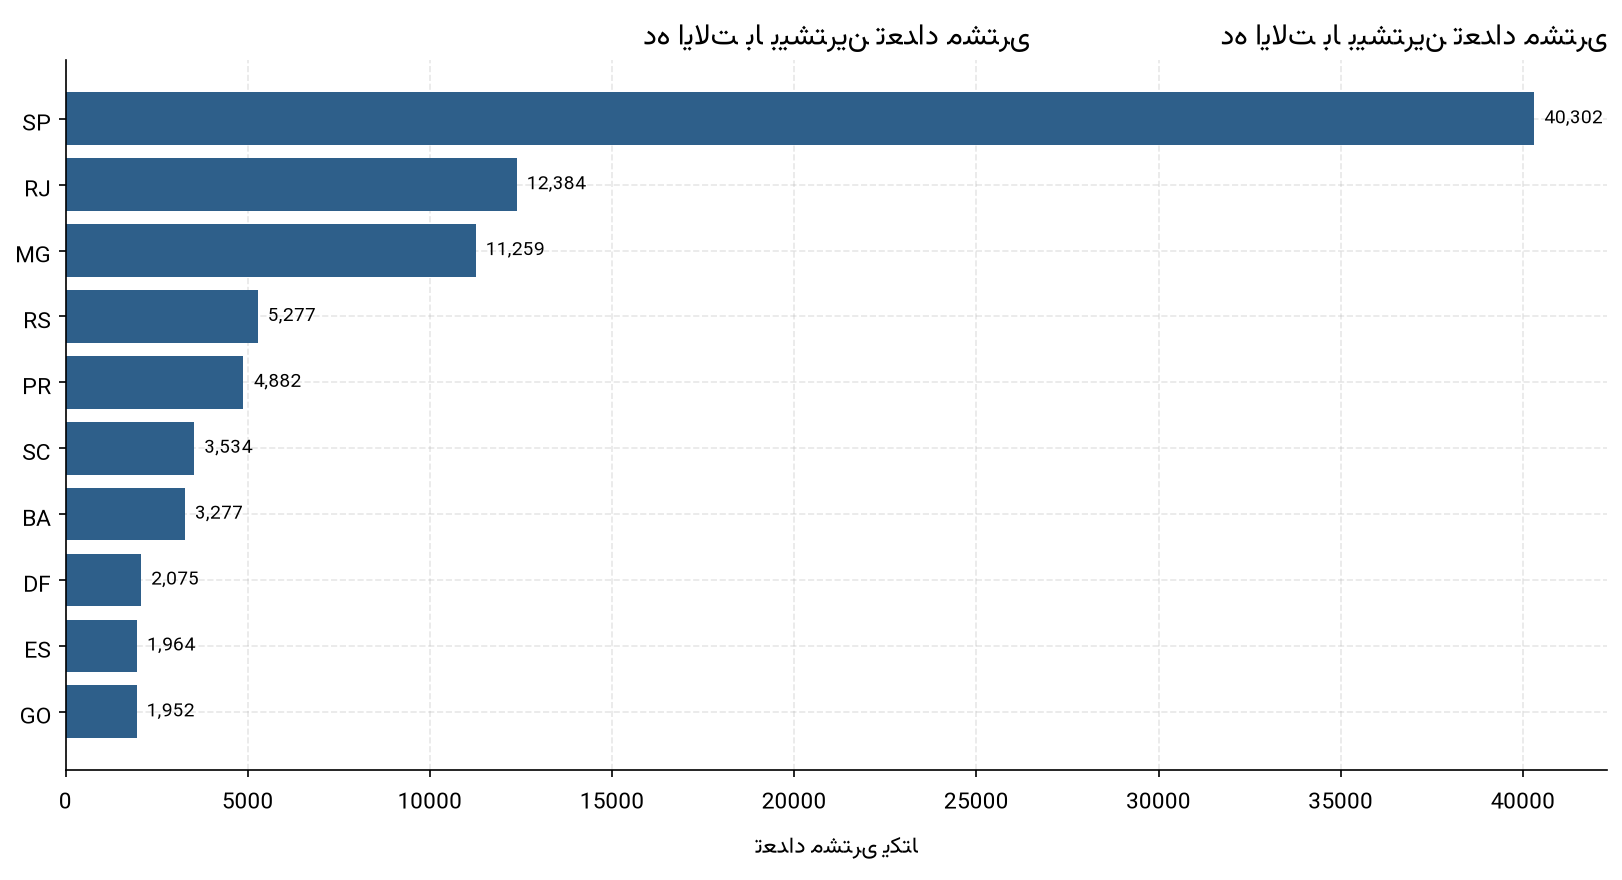

نمودار ۵ - ده ایالت اول بر اساس تعداد مشتری یکتا (customer_unique_id)


In [7]:
display(Image(filename=str(FIGURES_DIR / "fig_05_state_customers.png"), width=920))
caption = FIGURES_DIR / "fig_05_state_customers.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

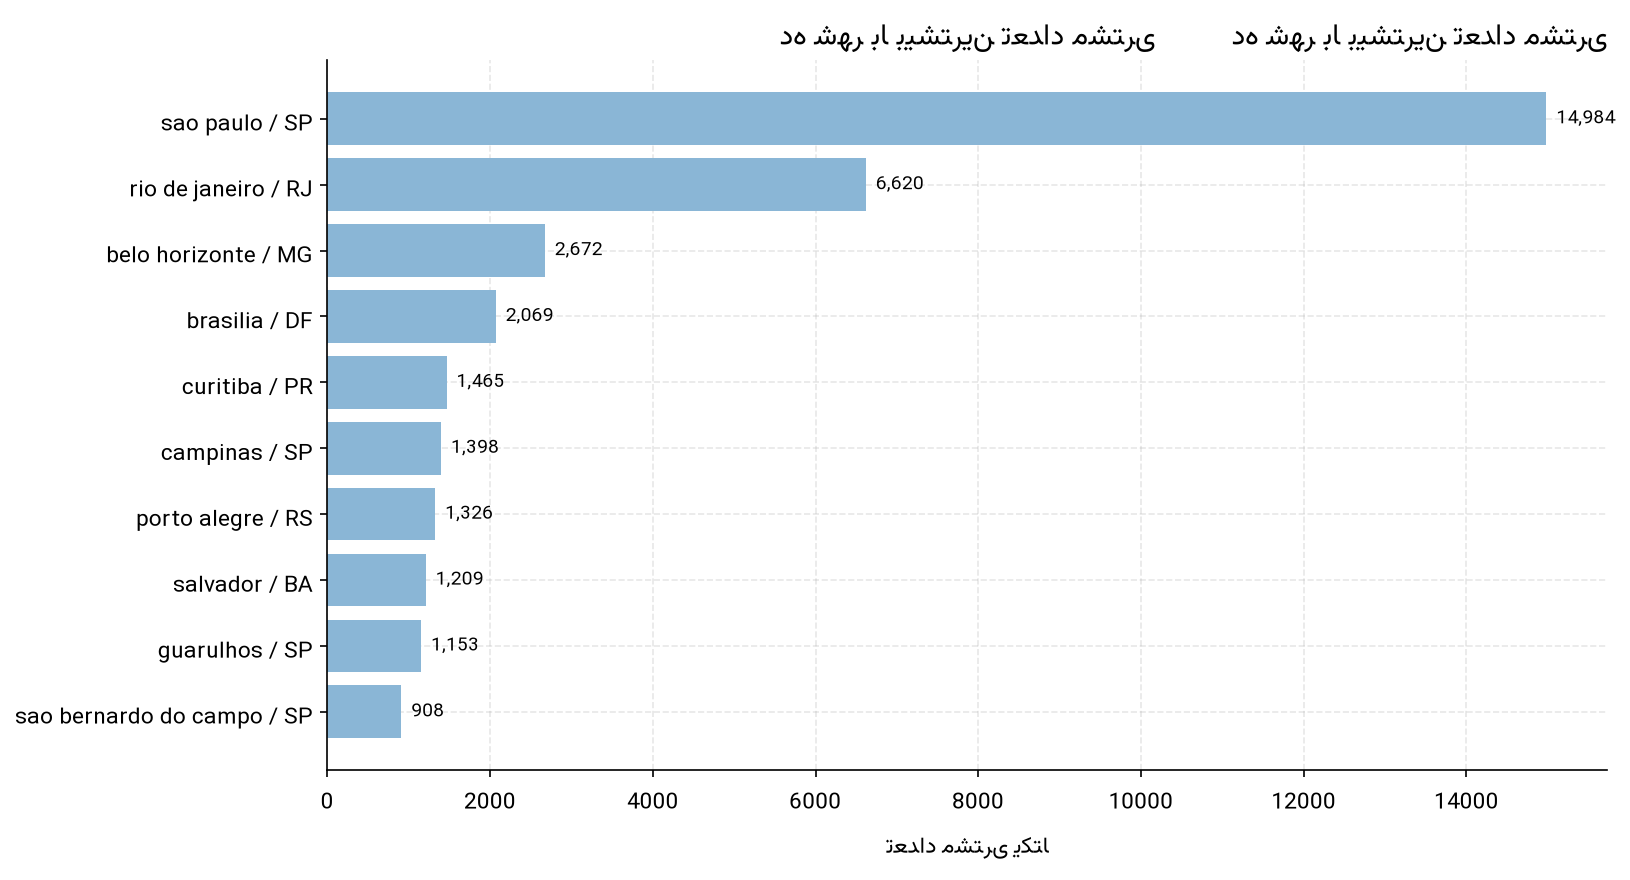

نمودار ۶ - ده شهر اول بر اساس تعداد مشتری یکتا


In [8]:
display(Image(filename=str(FIGURES_DIR / "fig_06_top_cities.png"), width=920))
caption = FIGURES_DIR / "fig_06_top_cities.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

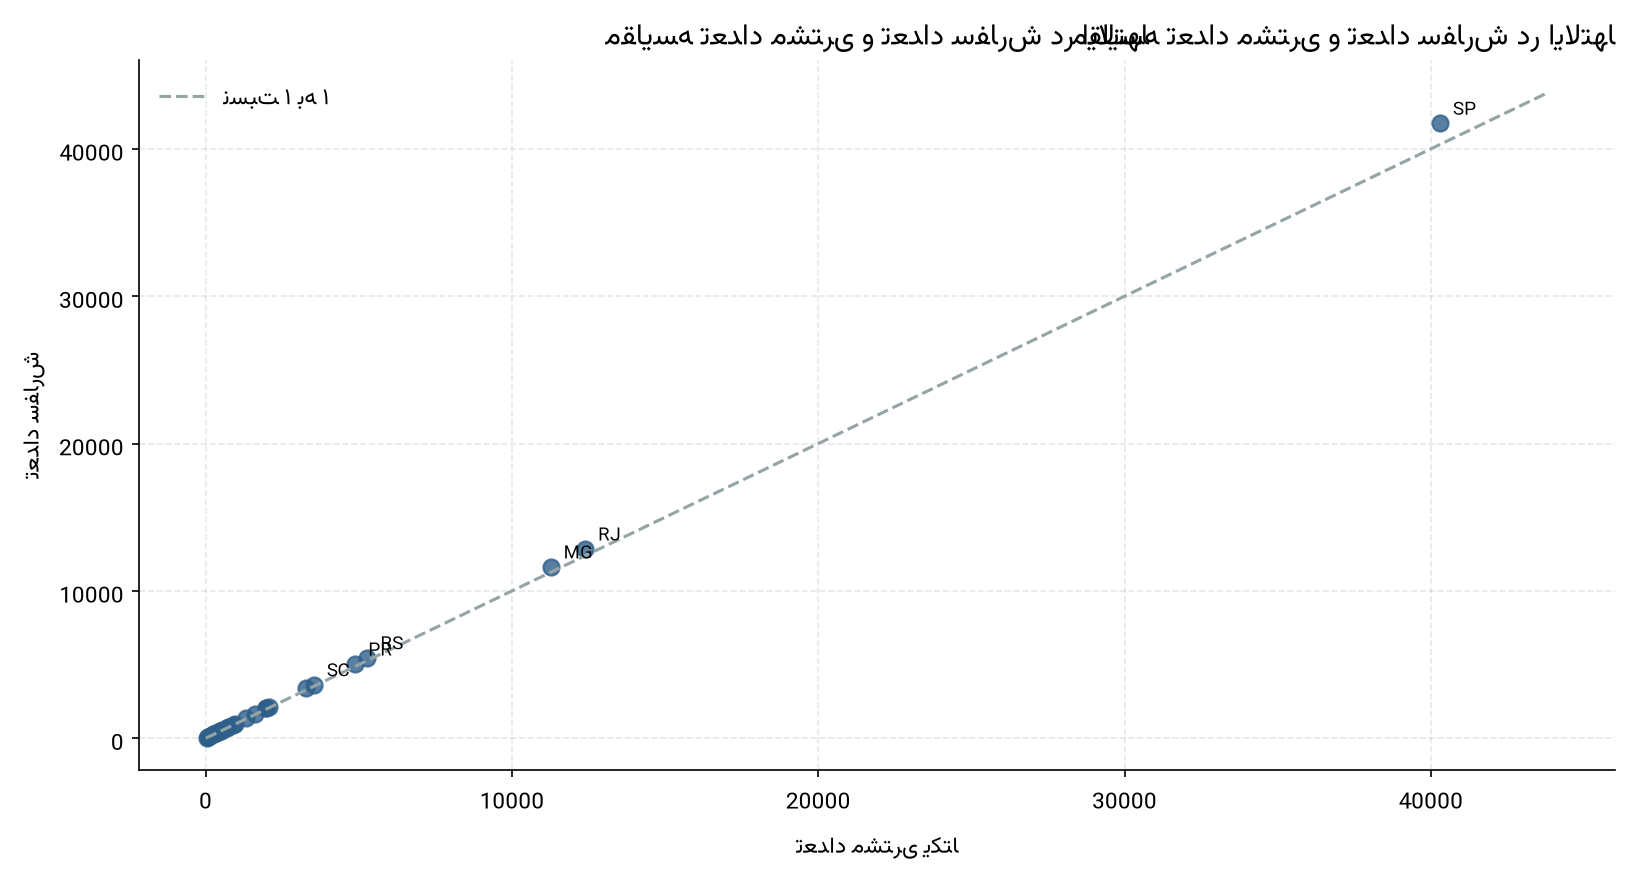

نمودار ۷ - رابطه تعداد مشتری و سفارش در هر ایالت؛ فاصله از خط، تفاوت سهم را نشان میدهد


In [9]:
display(Image(filename=str(FIGURES_DIR / "fig_07_state_customers_vs_orders.png"), width=920))
caption = FIGURES_DIR / "fig_07_state_customers_vs_orders.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۸. یافته‌های واقعی

- ۹۶٬۰۹۶ خریدار یکتا در ۹۹٬۴۴۱ ردیف مشتری ثبت شده‌اند؛ یعنی هر خریدار به‌طور میانگین ۱.۰۳۵ سفارش دارد.
- تنها ۲٬۹۹۷ نفر (۳.۱۲ درصد) بیش از یک سفارش ثبت کرده‌اند؛ بیشترین تعداد سفارش یک نفر ۱۷ است.
- ایالت SP با ۴۰٬۳۰۲ خریدار، ۴۱.۹۲ درصد بازار را در اختیار دارد.
- پنج ایالت اول (SP, RJ, MG, RS, PR) روی هم ۷۷.۰۸ درصد مشتریان و ۷۷.۱۸ درصد سفارش‌ها را پوشش می‌دهند.
- شهر سائوپائولو با ۱۴٬۹۸۴ خریدار، ۱۵.۵۹ درصد کل مشتریان را دارد.
- سهم مشتریان و سهم سفارش‌ها در سطح ایالت‌ها تقریباً یکسان است و تفاوت معناداری مشاهده نمی‌شود.

## ۹. تفسیر کسب‌وکاری

تمرکز بازار بالا است: هم مزیت کارایی در مناطق پرتراکم و هم ریسک وابستگی به یک بازار. نرخ خرید دوباره بسیار کم است و برنامه وفادارسازی می‌تواند ارزش هر مشتری را بالا ببرد.

## ۱۰. محدودیت‌های تحلیل

داده شامل هزینه بازاریابی، رقبا و تقاضای بالفعل مناطق کم‌مشتری نیست. کم بودن تعداد مشتری در یک ایالت به‌تنهایی اثبات فرصت رشد نیست و به‌عنوان فرصت تأییدشده معرفی نمی‌شود.

## ۱۱. نتیجه‌گیری

بازار فعال Olist عمدتاً در جنوب و جنوب‌شرق متمرکز است و سیاست رشد باید با در نظر گرفتن همین تمرکز و هزینه‌های لجستیک مناطق دور طراحی شود.